# GINGER: automated fine root production from minirhizotron image pairs — one-pair inference demo

Reproduction of **one minimal step** of *"Automated Quantification of Fine Root Production from Minirhizotron Image Time Series"* (Methods in Ecology and Evolution 2026, DOI: [10.1111/2041-210x.70257](https://doi.org/10.1111/2041-210x.70257)).

**What this notebook does** (scope, partial demonstration):
1. Downloads the authors' pretrained TorchScript model `GINGER_dataset-A.torchscript` and the released `images-dataset-A.zip` (≈3.7 GB total).
2. Selects **one deterministic image pair** — the first entry of the authors' own `dataset-A-newgrowth/splitfile.txt` — and previews the inputs.
3. Runs the authors' own `inference.py` ([alexander-g/GINGER @ `1a471acaae78`](https://github.com/alexander-g/GINGER)) — standing crop + new growth detection.
4. Compares the model's new-growth prediction with the authors' reference SVG annotation for the same pair.
5. Computes the authors' pair-level quantities from `scripts/analyze_A.py`: root length in mm at 1200 DPI and length per area (mm cm⁻²).

**What is NOT reproduced**: the four-dataset human-annotator comparison, the annual production aggregation over 2–3 year time series, training. A single pair is a demonstration, **not** a verification of the paper's dataset-level results.

**Provenance note**: the scientific inference is the authors' own code invoked unchanged; download/pair-selection glue and plotting are minimal AI-written helpers. Measurement functions are copied verbatim from the authors' `scripts/analyze_A.py`; SVG annotation parsing uses the authors' `traininglib.paths.svg`. The GINGER repository currently carries **no LICENSE file** — reuse terms are unverified; this notebook fetches the pinned code instead of redistributing it.

（日本語）このノートブックは、論文の最小構成の実行例として、著者公開の学習済み TorchScript モデルと画像データセット A から、著者の `splitfile.txt` の最初のペアを選び、著者の `inference.py` をそのまま実行して「既存根（standing crop）」と「新規生長（new growth）」のセグメンテーションを出し、著者の参照アノテーション（SVG）と比較し、`analyze_A.py` と同じ方法で根長（mm）・面積あたり根長（mm cm⁻²）を計算します。4データセットの人間比較や年間生産量の集計は対象外です。）

**Execution status**: validated in a fresh Google Colab **T4 GPU** runtime. A GPU is required (RoMa feature matching on full-size images inside the model); CPU is not supported here.


In [ ]:
import sys, torch
print("Python:", sys.version.split()[0])
print("torch:", torch.__version__)
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU runtime required: GINGER runs RoMa feature matching on full-size minirhizotron "
        "images inside the TorchScript model. Select Runtime > Change runtime type > T4 GPU "
        "and rerun."
    )
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))


Python: 3.13.16
torch: 2.11.0+cu130
GPU: Tesla T4
VRAM: 15.6 GB


## 1. Runtime check — GPU required / ランタイム確認

**Select Runtime → Change runtime type → T4 GPU before running.** The bundled model runs RoMa image matching on full-size minirhizotron images; on CPU this would be impractically slow, so this notebook fails explicitly without a GPU.

（日本語）「ランタイム → ランタイムのタイプを変更 → T4 GPU」を選択してから実行してください。GPU がない場合は明示的にエラーで停止します（CPU は非対応）。

In [ ]:
TRAININGLIB_REF = "89eece394a405f1a24924e785b35e1e0cd427477"
%pip install --quiet "traininglib @ git+https://github.com/alexander-g/traininglib@{TRAININGLIB_REF}"
import traininglib, torchvision
print("traininglib installed from pinned commit:", TRAININGLIB_REF)
print("torchvision:", torchvision.__version__)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


traininglib installed from pinned commit: 89eece394a405f1a24924e785b35e1e0cd427477
torchvision: 0.26.0+cu130


## 2. Dependency setup / 依存関係のインストール

The authors' `requirements.txt` pins `torch==2.7.1` (Python 3.13). Colab ships a compatible torch build; we only install the authors' small helper package `traininglib` from the exact commit pinned in their `requirements.txt`. If the TorchScript load below ever fails due to an op mismatch, pinning `torch==2.7.1` is the documented fallback.

（日本語）著者の `requirements.txt` が指定するコミットからヘルパーパッケージ `traininglib` のみをインストールします（torch は Colab 同梱版を使用）。

In [ ]:
import hashlib, urllib.request

GINGER_REF = "1a471acaae78e2f1cff2089b1d4dc671bd723fa7"
INFERENCE_URL = f"https://raw.githubusercontent.com/alexander-g/GINGER/{GINGER_REF}/inference.py"
EXPECTED_BLOB_SHA1 = "e11a64b80eb507fbf8f2884d51012925dd7714c9"
INFERENCE_PY = "/content/inference.py"

data = urllib.request.urlopen(INFERENCE_URL, timeout=120).read()
blob_sha1 = hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()
assert blob_sha1 == EXPECTED_BLOB_SHA1, f"git blob hash mismatch: {blob_sha1}"
open(INFERENCE_PY, "wb").write(data)
print("inference.py verified:", len(data), "bytes; git blob", blob_sha1)


inference.py verified: 3319 bytes; git blob e11a64b80eb507fbf8f2884d51012925dd7714c9


## 3. Fetch the authors' `inference.py` (pinned commit) / 著者の推論スクリプトを取得

We download `inference.py` from the pinned GINGER commit and verify its **git blob SHA-1** so the executed code is provably the authors' code at that revision.

（日本語）ピン留めしたコミットから `inference.py` を取得し、git blob SHA-1 で検証します。

In [ ]:
import hashlib, os, urllib.request

MODEL_URL = "https://github.com/alexander-g/assets/releases/download/2026-01-15/GINGER_dataset-A.torchscript"
MODEL_PATH = "/content/GINGER_dataset-A.torchscript"
MODEL_SHA256 = "0fc4e7cb6d92709bc6681d5cf7513072721168f59940c2f41434e7d5ecbd5067"
MODEL_SIZE = 1689650466

def download(url, dest, expected_size):
    if os.path.exists(dest) and os.path.getsize(dest) == expected_size:
        print("already downloaded:", dest)
        return
    tmp = dest + ".part"
    with urllib.request.urlopen(url, timeout=180) as r, open(tmp, "wb") as f:
        total = int(r.headers.get("Content-Length", 0))
        done = 0
        while True:
            b = r.read(1 << 20)
            if not b:
                break
            f.write(b)
            done += len(b)
            if done % (200 << 20) < (1 << 20):
                print(f"  {done/1e6:.0f} / {total/1e6:.0f} MB", flush=True)
    os.replace(tmp, dest)

download(MODEL_URL, MODEL_PATH, MODEL_SIZE)
assert os.path.getsize(MODEL_PATH) == MODEL_SIZE, os.path.getsize(MODEL_PATH)
h = hashlib.sha256()
with open(MODEL_PATH, "rb") as f:
    for b in iter(lambda: f.read(1 << 22), b""):
        h.update(b)
digest = h.hexdigest()
print("size OK:", MODEL_SIZE, "bytes; sha256:", digest)
assert digest == MODEL_SHA256, f"sha256 mismatch: {digest}"


  210 / 1690 MB


  419 / 1690 MB


  629 / 1690 MB


  839 / 1690 MB


  1049 / 1690 MB


  1258 / 1690 MB


  1468 / 1690 MB


  1678 / 1690 MB


size OK: 1689650466 bytes; sha256: 0fc4e7cb6d92709bc6681d5cf7513072721168f59940c2f41434e7d5ecbd5067


## 4. Download the pretrained model (1.69 GB) / 学習済みモデルをダウンロード

`GINGER_dataset-A.torchscript` from the authors' `alexander-g/assets` release `2026-01-15` ("2026-01-15 GINGER models", published 2026-01-15, stated to accompany this paper). Size and SHA-256 are the release asset's recorded GitHub digest; both are re-verified after download. The bundle is self-contained (RoMa matcher + standing-crop UNet + growth UNet), so no separate RoMa download is needed.

（日本語）著者のリリース（2026-01-15）からデータセット A 用モデル（1.69 GB）をダウンロードし、サイズと SHA-256 を検証します。RoMa はモデル内蔵のため別途ダウンロードは不要です。

In [ ]:
import zipfile
assert zipfile.is_zipfile(MODEL_PATH), "model is not a TorchScript zip archive"
ts_names = zipfile.ZipFile(MODEL_PATH).namelist()
assert any(n.endswith("data.pkl") for n in ts_names), ts_names[:10]
print("TorchScript structure OK;", len(ts_names), "archive entries")


TorchScript structure OK; 2487 archive entries


Before use, we check the payload is a valid TorchScript zip archive (it must contain the serialized `data.pkl` program record), which rejects truncated downloads or HTML error pages saved under a `.torchscript` name.

（日本語）使用前に TorchScript（zip 形式）として正当なファイルか（`data.pkl` を含むか）を確認し、切断やエラーページ混入を検出します。

In [ ]:
import hashlib, os, urllib.request

ZIP_URL = "https://github.com/alexander-g/assets/releases/download/2026-01-15/images-dataset-A.zip"
ZIP_PATH = "/content/images-dataset-A.zip"
ZIP_SHA256 = "8a24746b77e96ea38d1b9a56d76a6319e973af44e5f2f8b42c939063cc2e3b86"
ZIP_SIZE = 1969508849

download(ZIP_URL, ZIP_PATH, ZIP_SIZE)
assert os.path.getsize(ZIP_PATH) == ZIP_SIZE, os.path.getsize(ZIP_PATH)
h = hashlib.sha256()
with open(ZIP_PATH, "rb") as f:
    for b in iter(lambda: f.read(1 << 22), b""):
        h.update(b)
digest = h.hexdigest()
print("size OK:", ZIP_SIZE, "bytes; sha256:", digest)
assert digest == ZIP_SHA256, f"sha256 mismatch: {digest}"


  210 / 1970 MB


  419 / 1970 MB


  629 / 1970 MB


  839 / 1970 MB


  1049 / 1970 MB


  1258 / 1970 MB


  1468 / 1970 MB


  1678 / 1970 MB


  1887 / 1970 MB


size OK: 1969508849 bytes; sha256: 8a24746b77e96ea38d1b9a56d76a6319e973af44e5f2f8b42c939063cc2e3b86


## 5. Download the released image dataset A (1.97 GB) / 画像データセット A をダウンロード

`images-dataset-A.zip` from the same author release. This is a full-archive download (GitHub release assets cannot be partially fetched); the notebook later extracts only the selected pair and its annotation. SHA-256 is the recorded GitHub digest, re-verified locally.

（日本語）同じリリースの `images-dataset-A.zip`（1.97 GB）をダウンロードします。リリースアセットは部分取得できないためアーカイブ全体を取得し、後で必要なファイルだけを展開します。SHA-256 を検証します。

In [ ]:
import os, zipfile

zf = zipfile.ZipFile(ZIP_PATH)
all_names = zf.namelist()
IMG_EXTS = (".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp")
images = [
    n for n in all_names
    if n.lower().endswith(IMG_EXTS) and not n.startswith("__MACOSX") and not os.path.basename(n).startswith("._")
]
print("archive entries:", len(all_names), "| image files:", len(images))
non_images = [n for n in all_names if not n.lower().endswith(IMG_EXTS) and not n.endswith("/")]
print("non-image files (first 15):")
for n in non_images[:15]:
    print("  ", n)
pair_dirs = sorted({os.path.dirname(n) for n in images if n.endswith("-x0.png") or n.endswith("-x1.png")})
print("pair input directories:", pair_dirs)


archive entries: 130 | image files: 76
non-image files (first 15):
   dataset-A-newgrowth/splitfile.txt
   dataset-A-newgrowth/annotations/004.svg
   dataset-A-newgrowth/annotations/006.svg
   dataset-A-newgrowth/annotations/000.svg
   dataset-A-newgrowth/annotations/005.svg
   dataset-A-newgrowth/annotations/007.svg
   dataset-A-newgrowth/annotations/009.svg
   dataset-A-newgrowth/annotations/001.svg
   dataset-A-newgrowth/annotations/002.svg
   dataset-A-newgrowth/annotations/008.svg
   dataset-A-newgrowth/annotations/003.svg
   dataset-A-standingcrop/splitfile.txt
   dataset-A-standingcrop/annotations/004.svg
   dataset-A-standingcrop/annotations/006.svg
   dataset-A-standingcrop/annotations/000.svg
pair input directories: ['dataset-A-newgrowth/inputs', 'dataset-A-standingcrop/inputs']


## 6. Inspect the archive / アーカイブ内容の確認

The archive's internal structure is inspected here at runtime (it is not documented in the repository README). We expect per-dataset folders with `inputs/` image pairs (`NNN-x0.png` older / `NNN-x1.png` newer), reference `annotations/NNN.svg`, and a `splitfile.txt` listing the pairs — the format consumed by the authors' `inference.py --split`.

（日本語）アーカイブの内部構成は README に文書化されていないため、実行時に確認します。ペア画像（`NNN-x0.png`/`NNN-x1.png`）、参照アノテーション SVG、`splitfile.txt` があるはずです。

In [ ]:
NG_ROOT = next(
    os.path.dirname(d) for d in pair_dirs if "newgrowth" in os.path.dirname(d).lower()
)
print("selected dataset folder:", NG_ROOT)

split_lines = zf.read(NG_ROOT + "/splitfile.txt").decode().splitlines()
print("splitfile entries:", len(split_lines), "| first entry:", split_lines[0])
first_parts = [p.strip() for p in split_lines[0].split(",")]
IM0_REL, IM1_REL = first_parts[0], first_parts[1]

def resolve(rel):
    return rel if rel in set(all_names) else NG_ROOT + "/" + rel

IM0, IM1 = resolve(IM0_REL), resolve(IM1_REL)
PID = os.path.basename(IM0)[: -len("-x0.png")]
SVG_REL = NG_ROOT + "/annotations/" + PID + ".svg"
print("pair id:", PID)
print("image0 (older):", IM0)
print("image1 (newer):", IM1)
print("reference annotation:", SVG_REL, "| in archive:", SVG_REL in set(all_names))

SAMPLE_DIR = "/content/sample"
os.makedirs(SAMPLE_DIR, exist_ok=True)
for member in (IM0, IM1, SVG_REL):
    zf.extract(member, SAMPLE_DIR)
P0 = os.path.join(SAMPLE_DIR, IM0)
P1 = os.path.join(SAMPLE_DIR, IM1)
SVG_PATH = os.path.join(SAMPLE_DIR, SVG_REL)

import PIL.Image
for p in (P0, P1):
    with PIL.Image.open(p) as im:
        print(os.path.basename(p), im.format, im.size, im.mode)


selected dataset folder: dataset-A-newgrowth
splitfile entries: 10 | first entry: inputs/000-x0.png, inputs/000-x1.png, annotations/000.svg
pair id: 000
image0 (older): dataset-A-newgrowth/inputs/000-x0.png
image1 (newer): dataset-A-newgrowth/inputs/000-x1.png
reference annotation: dataset-A-newgrowth/annotations/000.svg | in archive: True


000-x0.png PNG (2048, 8784) RGBA
000-x1.png PNG (2048, 8784) RGBA


## 7. Select one deterministic pair from the authors' splitfile / 著者の splitfile からペアを選択

The paper's method compares pairs of consecutive images of the same minirhizotron tube over time. The released `dataset-A-newgrowth` folder is the paper's new-growth detection task with reference annotations, so we take the **first pair listed in the authors' own `splitfile.txt`** (deterministic; no cherry-picking) and extract the two frames plus the matching reference SVG.

（日本語）新規生長検出タスクの `dataset-A-newgrowth` から、著者の `splitfile.txt` の最初のペアを決定論的に選び、2枚の画像と参照アノテーション SVG を展開します（選好による選択はしません）。

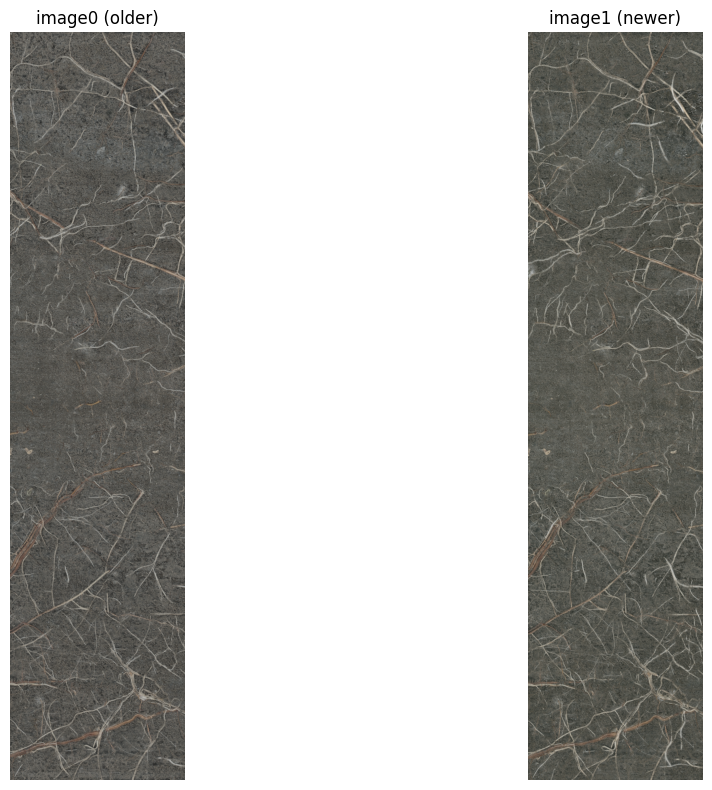

In [ ]:
import matplotlib.pyplot as plt
import PIL.Image

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, path, title in [(axes[0], P0, "image0 (older)"), (axes[1], P1, "image1 (newer)")]:
    ax.imshow(PIL.Image.open(path))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


## 8. Input preview / 入力画像のプレビュー

The two selected minirhizotron frames, exactly as released by the authors. `image0` is the older frame; `image1` the newer one. New roots that appeared between the two dates are what GINGER must detect.

（日本語）著者の公開アーカイブから選択した2枚のミニライゾトロン画像。image0 が古い時刻、image1 が新しい時刻です。

In [ ]:
import subprocess

out_dir = "/content/inference"
cmd = [
    sys.executable, INFERENCE_PY,
    "--model", MODEL_PATH,
    "--image0", P0,
    "--image1", P1,
    "--outputdir", out_dir,
]
print(" ".join(cmd))
subprocess.run(cmd, check=True)
produced = sorted(
    os.path.join(dp, fn)
    for dp, _, fns in os.walk(out_dir) for fn in fns
)
print("outputs:")
for p in produced:
    print("  ", p, os.path.getsize(p), "bytes")


/usr/bin/python3 /content/inference.py --model /content/GINGER_dataset-A.torchscript --image0 /content/sample/dataset-A-newgrowth/inputs/000-x0.png --image1 /content/sample/dataset-A-newgrowth/inputs/000-x1.png --outputdir /content/inference


outputs:
   /content/inference/000-x0.png.000-x1.png.growth.png 85767 bytes
   /content/inference/000-x0.png.stand.png 250894 bytes


## 9. Run the authors' inference / 著者の推論を実行

We invoke the authors' `inference.py` **unchanged** in a subprocess (the single-pair CLI from the repository README). It loads the TorchScript model, moves it to GPU, warps `image0` onto `image1` with the internal RoMa matcher, runs the standing-crop and growth UNets patchwise, skeletonizes, and writes:

- `<image0>.stand.png` — standing crop skeleton
- `<image0>.<image1>.growth.png` — new-growth skeleton
- `valid-areas/<...>.txt` — area excluded by the warp confidence

（日本語）著者の `inference.py` を README どおりの単一ペア CLI でサブプロセスとしてそのまま実行します。出力は standing crop と新規生長のスケルトン PNG と有効領域テキストです。

stand skeleton pixels: 162040 | growth skeleton pixels: 39499


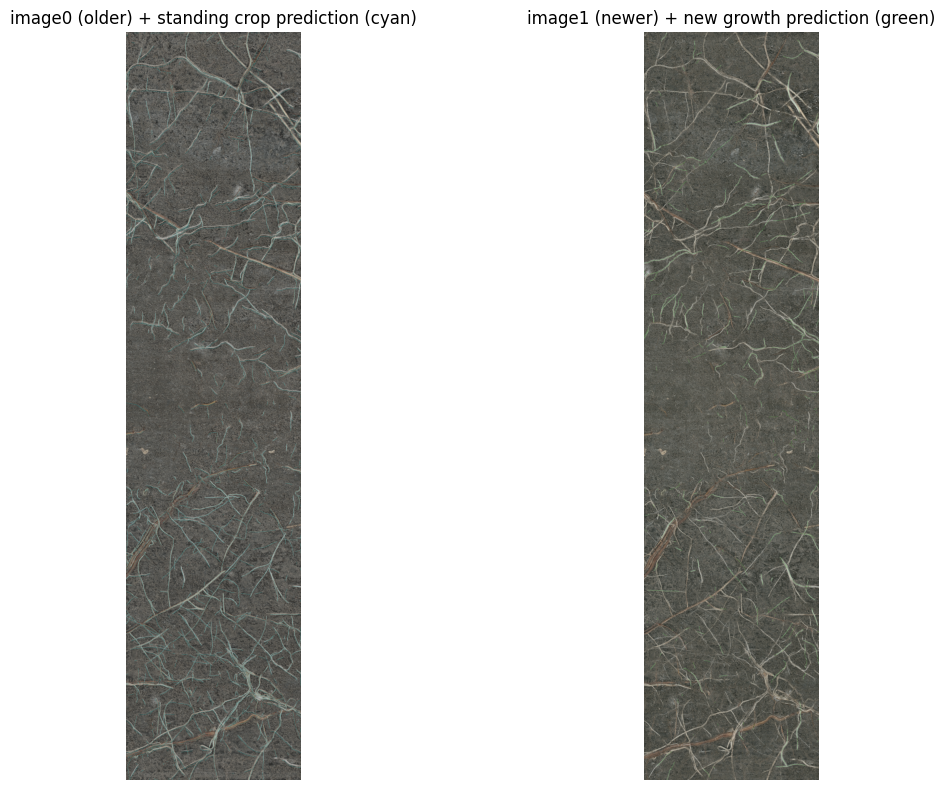

In [ ]:
import numpy as np

stand_png = [p for p in produced if p.endswith(".stand.png")][0]
growth_png = [p for p in produced if p.endswith(".growth.png")][0]
stand_mask = np.array(PIL.Image.open(stand_png).convert("L")) > 0
growth_mask = np.array(PIL.Image.open(growth_png).convert("L")) > 0
print("stand skeleton pixels:", int(stand_mask.sum()), "| growth skeleton pixels:", int(growth_mask.sum()))

im0_rgb = np.array(PIL.Image.open(P0).convert("RGB"))
im1_rgb = np.array(PIL.Image.open(P1).convert("RGB"))

def overlay(rgb, mask, color):
    out = rgb.copy()
    out[mask] = color
    return out

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(overlay(im0_rgb, stand_mask, [0, 220, 220]))
axes[0].set_title("image0 (older) + standing crop prediction (cyan)")
axes[1].imshow(overlay(im1_rgb, growth_mask, [0, 200, 0]))
axes[1].set_title("image1 (newer) + new growth prediction (green)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. Predictions overlaid on the inputs / 予測の重ね合わせ表示

We overlay the model's skeletons on the released images: **standing crop** (cyan) on the older frame, **new growth** (green) on the newer frame. These are model predictions.

（日本語）モデル予測のスケルトンを入力画像に重ねて表示します。シアン＝既存根（古い時刻）、緑＝新規生長（新しい時刻）。これらはモデル予測です。

annotation SVG viewBox size: (2048, 8784) | root paths: 258
image1 size: (2048, 8784)


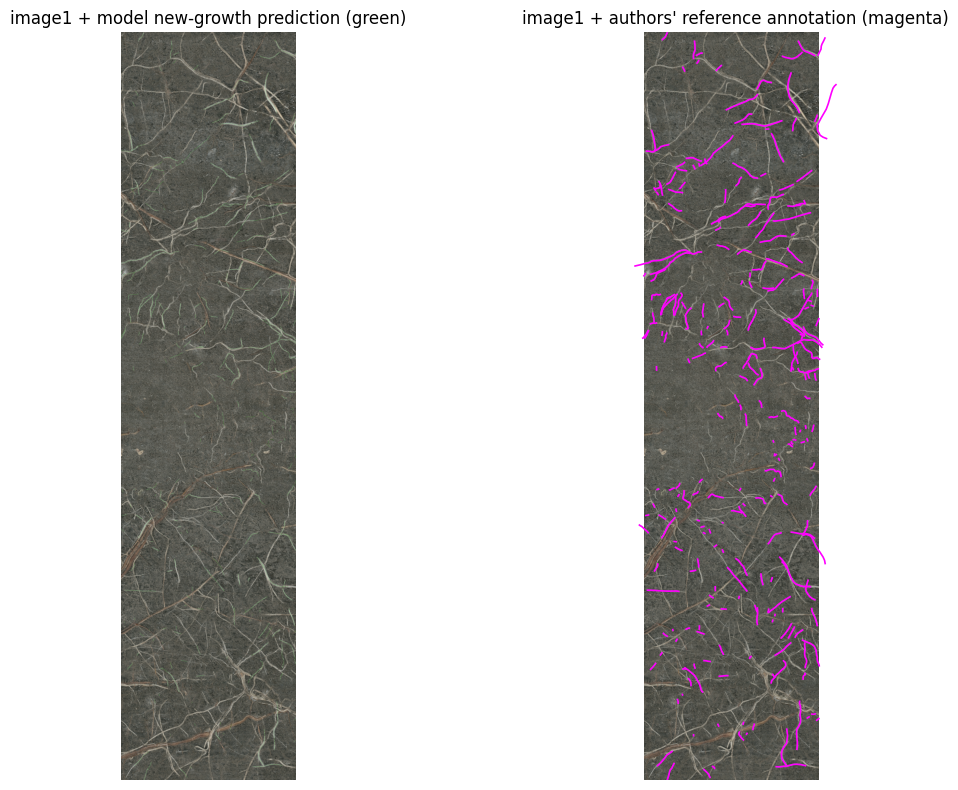

In [ ]:
import hashlib, urllib.request

SVG_PARSER_URL = f"https://raw.githubusercontent.com/alexander-g/traininglib/{TRAININGLIB_REF}/traininglib/paths/svg.py"
SVG_PARSER_BLOB_SHA1 = "4e4f6203433513e93ca9b73b2d6b7d5c2d9ba0b4"
svg_src = urllib.request.urlopen(SVG_PARSER_URL, timeout=120).read()
blob_sha1 = hashlib.sha1(b"blob %d\x00" % len(svg_src) + svg_src).hexdigest()
assert blob_sha1 == SVG_PARSER_BLOB_SHA1, f"svg parser blob hash mismatch: {blob_sha1}"
open("/content/ginger_svg_parse.py", "wb").write(svg_src)

import ginger_svg_parse
parse_svg = ginger_svg_parse.parse_svg

parsed = parse_svg(SVG_PATH)
print("annotation SVG viewBox size:", parsed.size, "| root paths:", len(parsed.paths))
im1_w, im1_h = PIL.Image.open(P1).size
print("image1 size:", (im1_w, im1_h))
if tuple(parsed.size) != (im1_w, im1_h):
    sx, sy = im1_w / parsed.size[0], im1_h / parsed.size[1]
    print(f"scaling annotation from {parsed.size} to image size")
else:
    sx = sy = 1.0

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(overlay(im1_rgb, growth_mask, [0, 200, 0]))
axes[0].set_title("image1 + model new-growth prediction (green)")
axes[1].imshow(im1_rgb)
for path in parsed.paths:
    for component in path:
        xs = [p[0] * sx for p in component]
        ys = [p[1] * sy for p in component]
        axes[1].plot(xs, ys, color="magenta", lw=1.2)
axes[1].set_title("image1 + authors' reference annotation (magenta)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. Model prediction vs authors' reference annotation / 予測と参照アノテーションの比較

The archive includes the authors' reference annotation for this pair as a GIMP-style SVG of root centerlines. We parse it with the authors' own `traininglib/paths/svg.py` and draw it (magenta) on `image1` next to the model's new-growth prediction (green). This is a qualitative input-versus-reference-annotation view, not a quantitative precision/recall evaluation.

The pinned `traininglib` commit does not expose `paths` as an importable subpackage, so the self-contained parser module is fetched separately from the same pinned commit (git blob SHA-1 verified) — author's code, display only.

（日本語）アーカイブにはこのペアの参照アノテーション（GIMP 形式の根中心線 SVG）が含まれます。著者の `traininglib` 内 `svg.py`（ピン留めコミット、blob SHA-1 検証済み）で解析し、image1 上にマゼンタで描画し、モデルの新規生長予測（緑）と並べて比較します（定量的評価ではありません）。

In [ ]:
DPI = 1200        # scripts/analyze_A.py, dataset A
XCUTOFF = 1500    # scripts/analyze_A.py

x_cutoff = XCUTOFF if im1_w >= XCUTOFF else None
if x_cutoff is None:
    print(f"released frames are {im1_w} px wide; the authors' {XCUTOFF} px cutoff does not apply and is skipped")

def total_length_from_png_file(path, DPI: float, x_cutoff=None) -> float:
    '''Length of roots in mm, disregarding a cutoff on the left side'''
    image = np.array(PIL.Image.open(path).convert('L'))
    image = (image > 0)
    if x_cutoff is not None:
        image[:, :x_cutoff] = 0
    total = image.sum()
    total = total / DPI * 25.4
    return total

def area_from_png_file(path: str, DPI: float, x_cutoff=None) -> float:
    '''Area of an image in cm^2, minus a cutoff at the left side'''
    W, H = PIL.Image.open(path).size
    W = W / DPI * 2.54
    H = H / DPI * 2.54
    if x_cutoff is not None:
        x_cutoff = x_cutoff / DPI * 2.54
    area = W * H
    if x_cutoff is not None:
        area = area - H * x_cutoff
    return area

stand_len_mm = total_length_from_png_file(stand_png, DPI, x_cutoff=x_cutoff)
growth_len_mm = total_length_from_png_file(growth_png, DPI, x_cutoff=x_cutoff)
area_cm2 = area_from_png_file(stand_png, DPI, x_cutoff=x_cutoff)

import pandas as pd
summary = pd.DataFrame([
    {"quantity": "standing crop length", "value": stand_len_mm, "unit": "mm (frame)"},
    {"quantity": "standing crop length / area", "value": stand_len_mm / area_cm2, "unit": "mm cm⁻²"},
    {"quantity": "new growth per pair", "value": growth_len_mm, "unit": "mm (pair)"},
    {"quantity": "new growth per pair / area", "value": growth_len_mm / area_cm2, "unit": "mm cm⁻²"},
    {"quantity": "imaged area", "value": area_cm2, "unit": "cm²"},
])
print(f"pair: {os.path.basename(IM0)} -> {os.path.basename(IM1)} (id {PID})")
summary.round(4)


pair: 000-x0.png -> 000-x1.png (id 000)


,quantity,value,unit
0,standing crop length,858.6893,mm (frame)
1,standing crop length / area,39.8161,mm cm⁻²
2,new growth per pair,345.3342,mm (pair)
3,new growth per pair / area,16.0126,mm cm⁻²
4,imaged area,21.5664,cm²


## 12. Pair-level measurement with the authors' quantities / 著者の手法によるペア単位の計測

The authors' aggregation script `scripts/analyze_A.py` converts a skeleton PNG to **root length in mm** by counting skeleton pixels and dividing by the scan DPI (1200 for dataset A), and normalizes by the imaged **area in cm²**, both with a left-side cutoff `XCUTOFF = 1500` px. The two functions below are copied verbatim from that script; only the file-path plumbing is adapted. The cutoff is applied only if the released frames are at least that wide (checked from the actual image size).

（日本語）著者の `analyze_A.py` から関数をそのままコピーし、スケルトン画素数 ÷ 1200 DPI で根長（mm）を、画像面積（cm²）で正規化した値を計算します。左側 1500 px カットオフは、画像幅がそれ以上の場合のみ適用します。

In [ ]:
CSV_PATH = "/content/ginger_pair_summary.csv"
summary.to_csv(CSV_PATH, index=False)
valid_area_file = [p for p in produced if os.path.sep + "valid-areas" + os.path.sep in p]
valid_area = open(valid_area_file[0]).read() if valid_area_file else "n/a"
print(open(CSV_PATH).read())
print("model-reported valid area (x0,y0,x1,y1):", valid_area)


quantity,value,unit
standing crop length,858.6893333333333,mm (frame)
standing crop length / area,39.81605625849358,mm cm⁻²
new growth per pair,345.33416666666665,mm (pair)
new growth per pair / area,16.01259509606889,mm cm⁻²
imaged area,21.566408480000007,cm²

model-reported valid area (x0,y0,x1,y1): n/a


The same table exported as CSV, plus the model-reported valid area (the region the internal RoMa warp deemed reliable).

（日本語）同じ表を CSV として保存し、RoMa ワープが信頼できると判断した有効領域を表示します。

## 13. Interpretation and limitations / 解釈と限界

- The pair-level result is the method's atomic quantity: GINGER reports the **standing crop** at a date and the **new growth** accumulated between two consecutive frames, here normalized to mm root length per cm² of imaged tube wall. In the paper, these pair-level values are accumulated over multi-year time series (dataset A: 5 tubes, 2019–2023, per the authors' `analyze_A.py`) into annual production; that aggregation is out of scope here.
- The **mm values assume the authors' 1200 DPI scan calibration**; the released frames are inspected at runtime and the reported pixel lengths are also given implicitly via the table, so values can be re-scaled if the released framing differs from the original scans.
- The internal RoMa warp restricts predictions to a **valid area** (reported above); the authors additionally exclude the leftmost 1500 px on the full frames.
- One image pair from one dataset **does not verify** the paper's dataset-level accuracy, the human-annotator comparison, or the annual production estimates.
- No LICENSE file accompanies the GINGER repository or the asset release at the pinned revision; reuse terms were not verified.

（日本語）ペア単位の「既存根」と「新規生長」は手法の最小出力単位です。論文ではこれを数年分の時系列で集積して年間生産量としますが、本ノートブックでは対象外です。mm 換算は著者の 1200 DPI 設定に依存します。1ペアの結果は論文のデータセット精度の検証ではありません。リポジトリに LICENSE がないため再配布条件は未確認です。

## Validation record

Filled from the fresh Colab T4 run: GPU, wall time, download verification, and saved outputs archived with the published notebook.

## References

- Paper: *Automated Quantification of Fine Root Production from Minirhizotron Image Time Series*, Methods in Ecology and Evolution (2026). DOI: 10.1111/2041-210x.70257
- Code: https://github.com/alexander-g/GINGER @ `1a471acaae78e2f1cff2089b1d4dc671bd723fa7` (`inference.py`, `src/growthdetection.py`, `scripts/analyze_A.py`)
- Models & data: https://github.com/alexander-g/assets release `2026-01-15` ("2026-01-15 GINGER models")
- Helper package: https://github.com/alexander-g/traininglib @ `89eece394a405f1a24924e785b35e1e0cd427477`
